In [61]:
import numpy as np
import matplotlib.pyplot as plt
import random
import math

np.random.seed(42)
random.seed(42)

In [62]:
def gaussian_num(mu, sigma, n):
    """Box-Muller generator for 1-D N(mu, sigma^2) samples (from Assignment 4)."""
    samples = []
    while len(samples) < n:
        u1 = random.uniform(-1, 1)
        u2 = random.uniform(-1, 1)
        s = u1**2 + u2**2
        if 0 < s < 1:
            k = math.sqrt(-2 * math.log(s) / s)
            x = u1 * k
            y = u2 * k
            samples.append(mu + sigma * x)
            if len(samples) < n:
                samples.append(mu + sigma * y)
    return samples[:n]


def sigma_half(Sigma):
    """Matrix square root of a covariance matrix via eigendecomposition:
    Sigma = V diag(lambda) V^T  =>  Sigma^(1/2) = V diag(sqrt(lambda)) V^T """
    eigvals, eigvecs = np.linalg.eigh(Sigma)
    eigvals = np.clip(eigvals, 0, None)   # guard against tiny negative numerical noise
    return eigvecs @ np.diag(np.sqrt(eigvals)) @ eigvecs.T


def generate_class_data(mu, Sigma, n):
    """Generate n points from N(mu, Sigma) for any d-dimensional mu/Sigma,
    using independent Box-Muller draws + a linear transform (Y = AX + mu)."""
    mu = np.asarray(mu, dtype=float)
    d = len(mu)
    base = np.column_stack([gaussian_num(0.0, 1.0, n) for _ in range(d)])  # Cov = I
    S_half = sigma_half(np.asarray(Sigma, dtype=float))
    return mu + base @ S_half.T

In [63]:
def mle_estimate(X):
    """Maximum-likelihood estimates of mean and (full) covariance from data X (n_samples x d)."""
    N = X.shape[0]
    mu_hat = X.mean(axis=0)
    diff = X - mu_hat
    Sigma_hat = (diff.T @ diff) / N          # MLE divides by N, not N-1
    return mu_hat, Sigma_hat

In [64]:
def discriminant(X_grid, mu, Sigma, prior):
    """g_i(x) for every row of X_grid, given estimated (mu, Sigma, prior) of class i."""
    Sigma_inv = np.linalg.inv(Sigma)
    _, logdet = np.linalg.slogdet(Sigma)
    diff = X_grid - mu
    quad = np.einsum('ij,jk,ik->i', diff, Sigma_inv, diff)   # (x-mu)^T Sigma^-1 (x-mu) for every row
    return -0.5 * logdet - 0.5 * quad + np.log(prior)

In [65]:
def set_equal_limits(ax, all_points, pad=1.5):
    x_min, x_max = all_points[:, 0].min(), all_points[:, 0].max()
    y_min, y_max = all_points[:, 1].min(), all_points[:, 1].max()
    cx, cy = (x_min + x_max) / 2, (y_min + y_max) / 2
    half_range = max(x_max - x_min, y_max - y_min) / 2 + pad
    ax.set_xlim(cx - half_range, cx + half_range)
    ax.set_ylim(cy - half_range, cy + half_range)
    ax.set_aspect('equal', adjustable='box')


def confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for t, p in zip(y_true, y_pred):
        cm[t, p] += 1
    return cm   # rows = true class, columns = predicted class


def accuracy(cm):
    return np.trace(cm) / cm.sum()

In [66]:
def roc_curve_binary(scores, labels_binary):
    """One-vs-rest ROC curve. scores: continuous score (higher = more 'positive').
    labels_binary: 1 for the positive class, 0 for everything else.
    Returns (fpr, tpr) arrays tracing the curve from (0,0) to (1,1)."""
    order = np.argsort(-scores)                 # sort scores from highest to lowest
    labels_sorted = labels_binary[order]
    P = labels_binary.sum()                      # total positives
    N = len(labels_binary) - P                   # total negatives
    tps = np.cumsum(labels_sorted)                # running count of true positives
    fps = np.cumsum(1 - labels_sorted)            # running count of false positives
    tpr = tps / P if P > 0 else np.zeros_like(tps, dtype=float)
    fpr = fps / N if N > 0 else np.zeros_like(fps, dtype=float)
    tpr = np.concatenate([[0.0], tpr])            # start the curve at the origin
    fpr = np.concatenate([[0.0], fpr])
    return fpr, tpr


def auc_score(fpr, tpr):
    """Area under the ROC curve via the trapezoidal rule (no numpy.trapz dependency)."""
    return np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2.0)


def plot_roc_curves(name, y_true, g_scores, n_classes, colors=('tab:blue', 'tab:orange', 'tab:green')):
    """Plot one-vs-rest ROC curves for all classes on one axes. Returns dict of AUCs."""
    fig, ax = plt.subplots(figsize=(5.5, 5.5))
    aucs = {}
    for c in range(n_classes):
        binary_labels = (y_true == c).astype(int)
        fpr, tpr = roc_curve_binary(g_scores[:, c], binary_labels)
        auc_val = auc_score(fpr, tpr)
        aucs[c] = auc_val
        ax.plot(fpr, tpr, color=colors[c], lw=2,
                label=f"class {c+1} vs rest (AUC = {auc_val:.3f})")
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='chance (AUC = 0.5)')
    ax.set_xlim(-0.02, 1.02); ax.set_ylim(-0.02, 1.02)
    ax.set_aspect('equal')
    ax.set_xlabel('False Positive Rate')
    ax.set_ylabel('True Positive Rate')
    ax.set_title(f"ROC Curves (one-vs-rest)\n{name}")
    ax.legend(loc='lower right', fontsize=8)
    plt.tight_layout()
    plt.show()
    return aucs

In [67]:
def run_experiment(name, mus, Sigmas, n_per_class=10000, test_frac=0.2, seed=0):
    rng = np.random.default_rng(seed)
    n_classes = len(mus)

    X_train_list, y_train_list = [], []
    X_test_list, y_test_list = [], []

    for c in range(n_classes):
        Xc = generate_class_data(mus[c], Sigmas[c], n_per_class)
        idx = rng.permutation(n_per_class)
        n_test = int(n_per_class * test_frac)
        test_idx, train_idx = idx[:n_test], idx[n_test:]
        X_train_list.append(Xc[train_idx]); y_train_list.append(np.full(len(train_idx), c))
        X_test_list.append(Xc[test_idx]);   y_test_list.append(np.full(len(test_idx), c))

    X_train = np.vstack(X_train_list); y_train = np.concatenate(y_train_list)
    X_test  = np.vstack(X_test_list);  y_test  = np.concatenate(y_test_list)

    # ---- MLE parameter estimation per class, using TRAIN data only ----
    mu_hats, Sigma_hats, priors = [], [], []
    for c in range(n_classes):
        Xc = X_train[y_train == c]
        mu_hat, Sigma_hat = mle_estimate(Xc)
        mu_hats.append(mu_hat); Sigma_hats.append(Sigma_hat)
        priors.append(len(Xc) / len(X_train))

    # ---- classify the held-out test set ----
    g_test = np.column_stack([discriminant(X_test, mu_hats[c], Sigma_hats[c], priors[c])
                               for c in range(n_classes)])
    y_pred = np.argmax(g_test, axis=1)

    cm = confusion_matrix(y_test, y_pred, n_classes)
    acc = accuracy(cm)

    # ---- ROC curves (one-vs-rest), using the same g_test scores ----
    aucs = plot_roc_curves(name, y_test, g_test, n_classes)

    # ---- plot: decision regions + test points overlaid ----
    all_pts = np.vstack([X_train, X_test])
    fig, ax = plt.subplots(figsize=(6.5, 6.5))
    set_equal_limits(ax, all_pts, pad=1.5)
    xlim, ylim = ax.get_xlim(), ax.get_ylim()
    xx, yy = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*ylim, 400))
    grid = np.column_stack([xx.ravel(), yy.ravel()])
    g_grid = np.column_stack([discriminant(grid, mu_hats[c], Sigma_hats[c], priors[c])
                               for c in range(n_classes)])
    region = np.argmax(g_grid, axis=1).reshape(xx.shape)

    colors = ['tab:blue', 'tab:orange', 'tab:green']
    ax.contourf(xx, yy, region, levels=np.arange(-0.5, n_classes, 1),
                colors=colors, alpha=0.18)
    for c in range(n_classes):
        pts = X_test[y_test == c]
        ax.scatter(pts[:, 0], pts[:, 1], s=10, alpha=0.6, color=colors[c],
                   label=f"class {c+1} (test)", edgecolors='none')
    misclassified = X_test[y_pred != y_test]
    if len(misclassified):
        ax.scatter(misclassified[:, 0], misclassified[:, 1], s=35, facecolors='none',
                   edgecolors='red', linewidths=1.2, label='misclassified')

    ax.set_xlabel('x1'); ax.set_ylabel('x2')
    ax.set_title(f"{name}\nTest accuracy = {acc*100:.2f}%")
    ax.legend(loc='upper left', fontsize=8)
    plt.tight_layout()
    plt.show()

    return mu_hats, Sigma_hats, priors, cm, acc, aucs

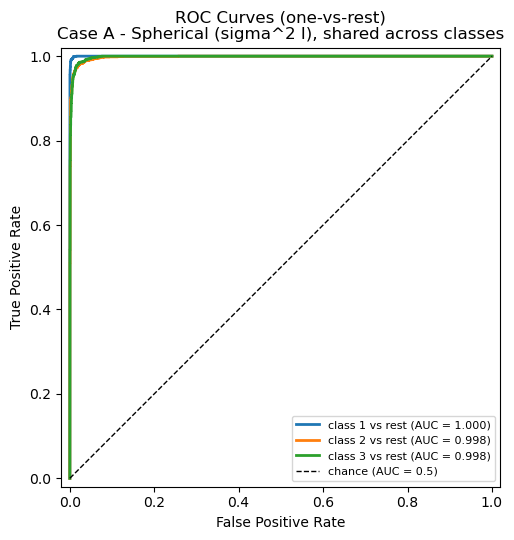

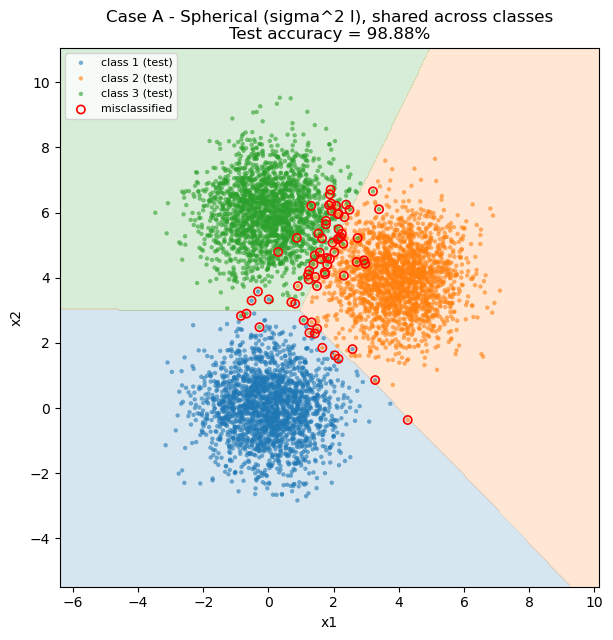

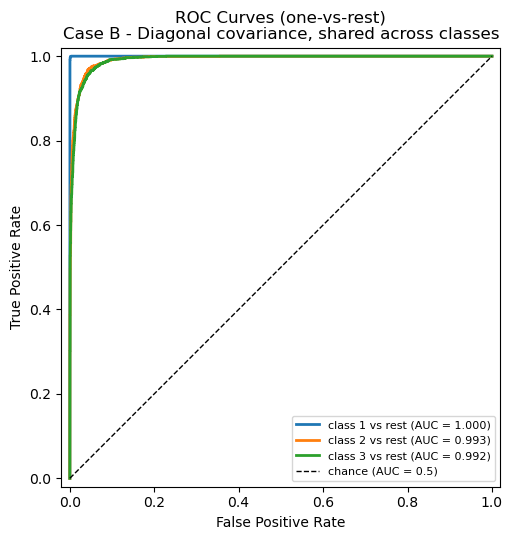

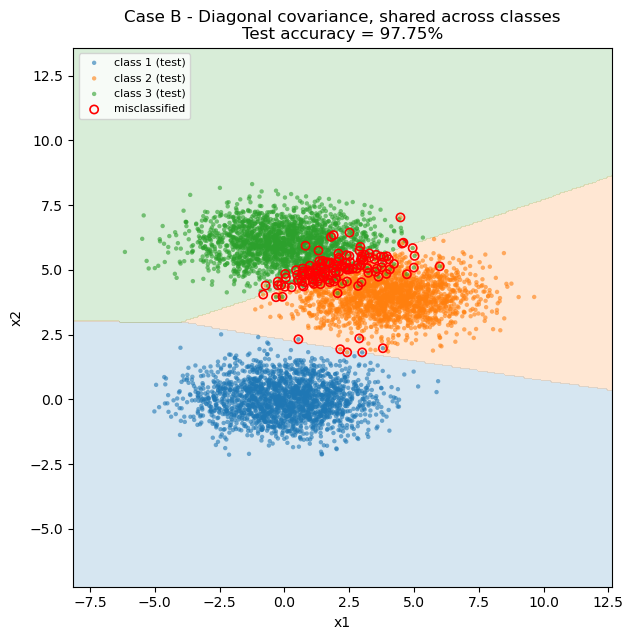

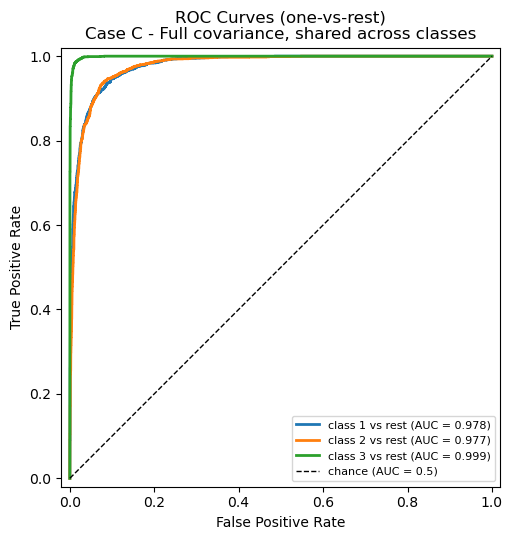

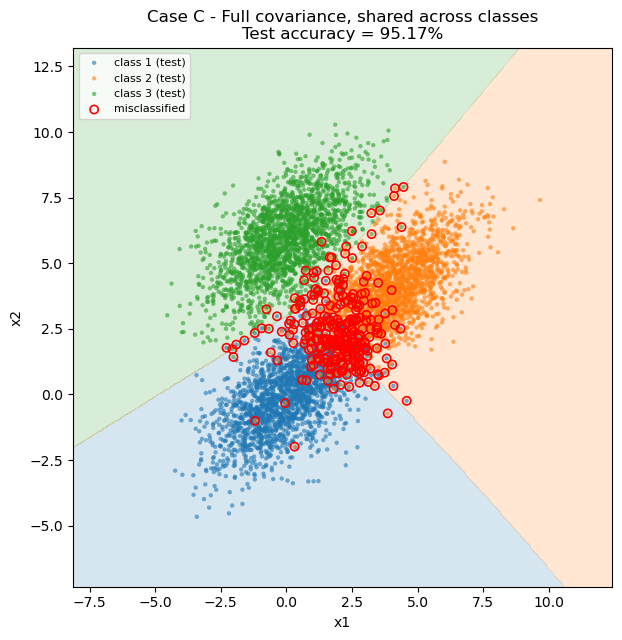

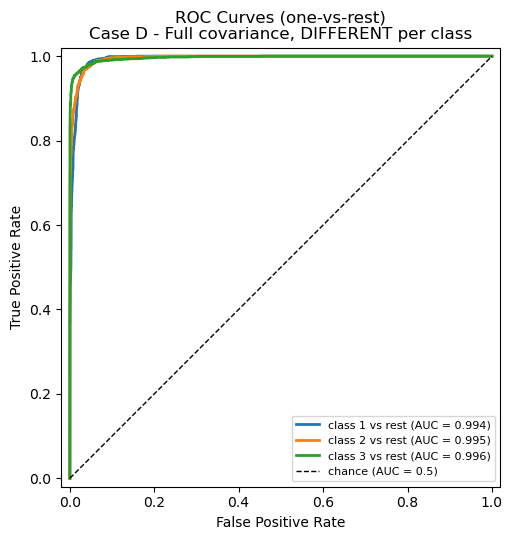

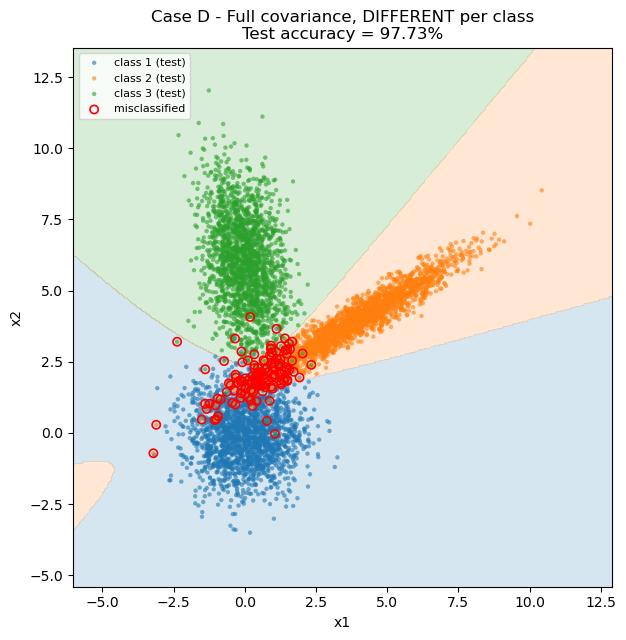

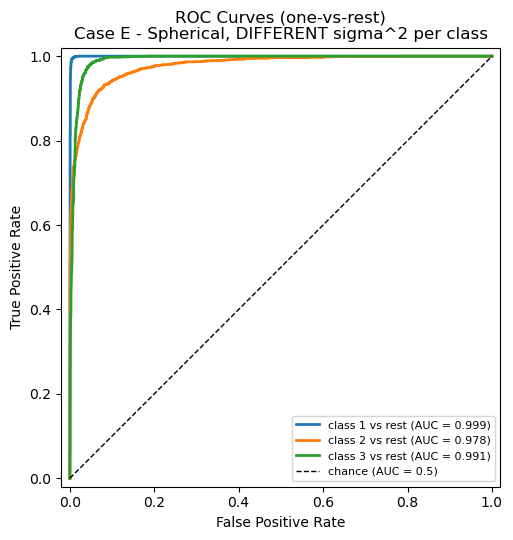

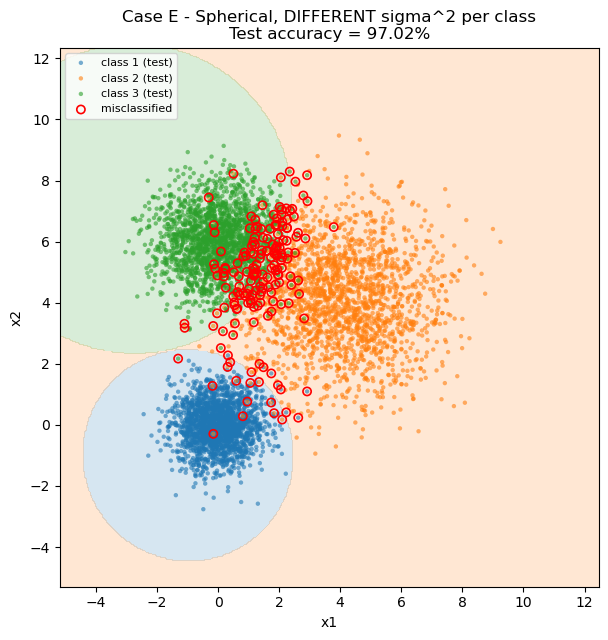

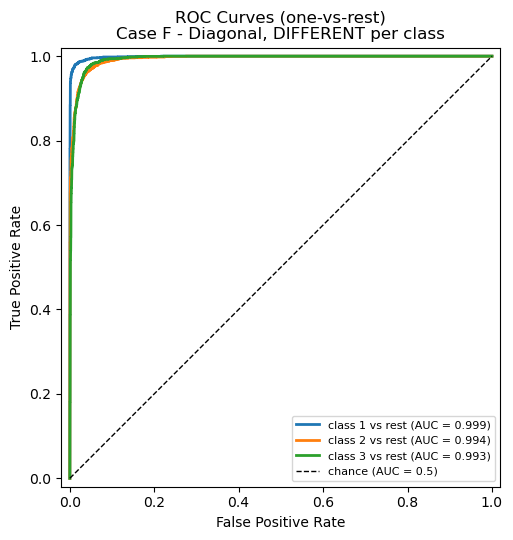

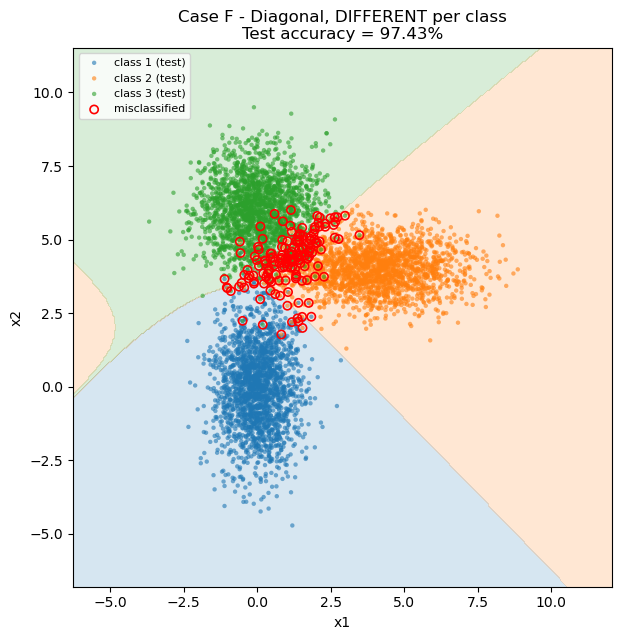

In [68]:
mus_common = [[0, 0], [4, 4], [0, 6]]
I2 = np.eye(2)

cases = {}
cases['Case A - Spherical (sigma^2 I), shared across classes'] = (
    mus_common, [1.0 * I2, 1.0 * I2, 1.0 * I2])

cases['Case B - Diagonal covariance, shared across classes'] = (
    mus_common, [np.diag([3.0, 0.5])] * 3)

Cshared = np.array([[2.0, 1.2], [1.2, 2.0]])
cases['Case C - Full covariance, shared across classes'] = (
    mus_common, [Cshared, Cshared, Cshared])

cases['Case D - Full covariance, DIFFERENT per class'] = (
    mus_common,
    [np.array([[1.0, 0.0], [0.0, 1.0]]),
     np.array([[3.0, 1.8], [1.8, 1.2]]),
     np.array([[0.5, -0.3], [-0.3, 2.5]])]
)

cases['Case E - Spherical, DIFFERENT sigma^2 per class'] = (
    mus_common,
    [0.5 * I2, 2.5 * I2, 1.0 * I2]
)

cases['Case F - Diagonal, DIFFERENT per class'] = (
    mus_common,
    [np.diag([0.5, 2.0]), np.diag([2.5, 0.5]), np.diag([1.0, 1.0])]
)

results = {}
for name, (mus, Sigmas) in cases.items():
    mu_hats, Sigma_hats, priors, cm, acc, aucs = run_experiment(name, mus, Sigmas,
                                                                 n_per_class=10000, seed=1)
    results[name] = dict(mus=mus, Sigmas=Sigmas, mu_hats=mu_hats,
                          Sigma_hats=Sigma_hats, priors=priors, cm=cm, acc=acc, aucs=aucs)

In [69]:
for name, r in results.items():
    print("=" * 70)
    print(name)
    print(f"Test accuracy: {r['acc']*100:.2f}%")
    print("Confusion matrix (rows=true, cols=predicted):")
    print(r['cm'])
    print("ROC AUC (one-vs-rest):", {f"class {c+1}": round(v, 4) for c, v in r['aucs'].items()})
    for c in range(3):
        print(f"\n  Class {c+1}:")
        print(f"    true mu    = {np.round(r['mus'][c], 3)}   | estimated mu_hat    = {np.round(r['mu_hats'][c], 3)}")
        print(f"    true Sigma =\n{np.array(r['Sigmas'][c])}")
        print(f"    Sigma_hat  =\n{np.round(r['Sigma_hats'][c], 3)}")
    print()

Case A - Spherical (sigma^2 I), shared across classes
Test accuracy: 98.88%
Confusion matrix (rows=true, cols=predicted):
[[1994    2    4]
 [   8 1962   30]
 [   4   19 1977]]
ROC AUC (one-vs-rest): {'class 1': 0.9999, 'class 2': 0.9979, 'class 3': 0.9981}

  Class 1:
    true mu    = [0 0]   | estimated mu_hat    = [ 0.005 -0.017]
    true Sigma =
[[1. 0.]
 [0. 1.]]
    Sigma_hat  =
[[0.991 0.003]
 [0.003 0.993]]

  Class 2:
    true mu    = [4 4]   | estimated mu_hat    = [3.994 3.998]
    true Sigma =
[[1. 0.]
 [0. 1.]]
    Sigma_hat  =
[[ 1.018 -0.004]
 [-0.004  1.   ]]

  Class 3:
    true mu    = [0 6]   | estimated mu_hat    = [3.00e-03 6.01e+00]
    true Sigma =
[[1. 0.]
 [0. 1.]]
    Sigma_hat  =
[[0.972 0.004]
 [0.004 0.989]]

Case B - Diagonal covariance, shared across classes
Test accuracy: 97.75%
Confusion matrix (rows=true, cols=predicted):
[[1996    4    0]
 [   2 1930   68]
 [   0   61 1939]]
ROC AUC (one-vs-rest): {'class 1': 1.0, 'class 2': 0.9929, 'class 3': 0.9919}

In [70]:
# ---- load the real dataset ----
train_data = np.loadtxt("trian.txt", delimiter=",")
dev_data   = np.loadtxt("dev.txt",   delimiter=",")

X_train_real = train_data[:, :2]
y_train_real = train_data[:, 2].astype(int) - 1   # convert labels 1,2,3 -> 0,1,2

X_test_real = dev_data[:, :2]
y_test_real = dev_data[:, 2].astype(int) - 1

n_classes_real = 3
print(f"Train: {X_train_real.shape[0]} points  |  Dev/Test: {X_test_real.shape[0]} points")
print("Train class counts:", np.bincount(y_train_real))
print("Dev   class counts:", np.bincount(y_test_real))

Train: 1050 points  |  Dev/Test: 300 points
Train class counts: [350 350 350]
Dev   class counts: [100 100 100]


In [71]:
mu_hats_real, Sigma_hats_real, priors_real = [], [], []
for c in range(n_classes_real):
    Xc = X_train_real[y_train_real == c]
    mu_hat, Sigma_hat = mle_estimate(Xc)
    mu_hats_real.append(mu_hat); Sigma_hats_real.append(Sigma_hat)
    priors_real.append(len(Xc) / len(X_train_real))
    print(f"Class {c+1}: N={len(Xc)}, prior={priors_real[c]:.3f}")
    print(f"  mu_hat    = {np.round(mu_hat, 2)}")
    print(f"  Sigma_hat =\n{np.round(Sigma_hat, 2)}\n")

Class 1: N=350, prior=0.333
  mu_hat    = [ 405.98 1205.09]
  Sigma_hat =
[[ 21302.39  33260.29]
 [ 33260.29 152374.25]]

Class 2: N=350, prior=0.333
  mu_hat    = [ 329.7  2076.25]
  Sigma_hat =
[[ 4059.18 -3767.58]
 [-3767.58 33133.75]]

Class 3: N=350, prior=0.333
  mu_hat    = [ 543.04 1730.48]
  Sigma_hat =
[[14439.62  1634.01]
 [ 1634.01 41178.73]]



In [72]:
g_test_real = np.column_stack([
    discriminant(X_test_real, mu_hats_real[c], Sigma_hats_real[c], priors_real[c])
    for c in range(n_classes_real)
])
y_pred_real = np.argmax(g_test_real, axis=1)

cm_real = confusion_matrix(y_test_real, y_pred_real, n_classes_real)
acc_real = accuracy(cm_real)

print(f"Dev-set accuracy: {acc_real*100:.2f}%")
print("Confusion matrix (rows=true class, cols=predicted class):")
print(cm_real)

Dev-set accuracy: 77.33%
Confusion matrix (rows=true class, cols=predicted class):
[[73  4 23]
 [ 5 78 17]
 [ 6 13 81]]


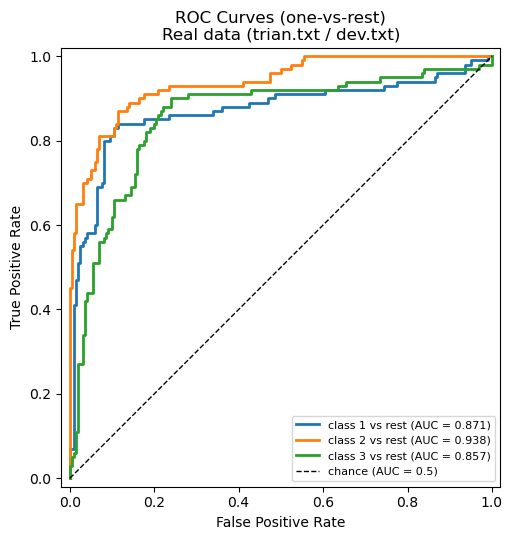

ROC AUC (one-vs-rest): {'class 1': 0.8712, 'class 2': 0.9378, 'class 3': 0.8566}


In [73]:
aucs_real = plot_roc_curves("Real data (trian.txt / dev.txt)", y_test_real, g_test_real, n_classes_real)
print("ROC AUC (one-vs-rest):", {f"class {c+1}": round(v, 4) for c, v in aucs_real.items()})

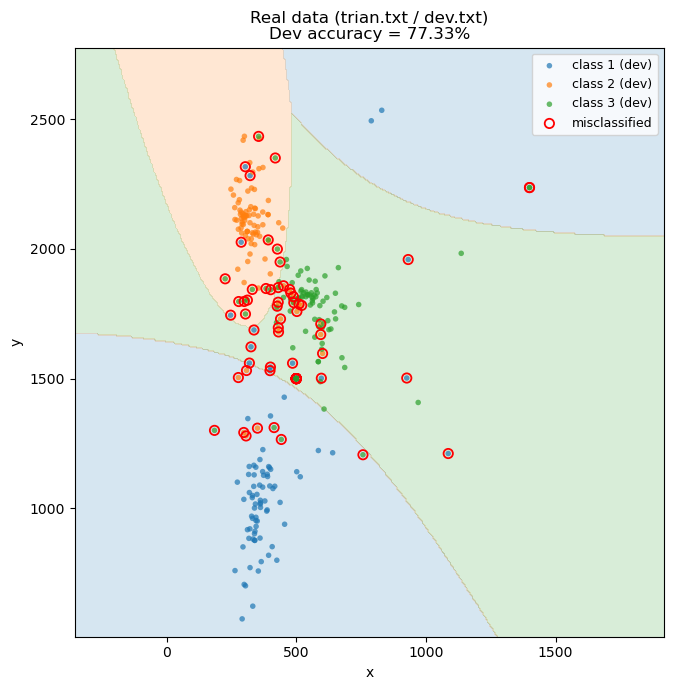

In [74]:
fig, ax = plt.subplots(figsize=(7, 7))
all_pts_real = np.vstack([X_train_real, X_test_real])
set_equal_limits(ax, all_pts_real, pad=50)   # bigger pad: real data is on a much larger numeric scale

xlim, ylim = ax.get_xlim(), ax.get_ylim()
xx, yy = np.meshgrid(np.linspace(*xlim, 400), np.linspace(*ylim, 400))
grid = np.column_stack([xx.ravel(), yy.ravel()])
g_grid_real = np.column_stack([
    discriminant(grid, mu_hats_real[c], Sigma_hats_real[c], priors_real[c])
    for c in range(n_classes_real)
])
region_real = np.argmax(g_grid_real, axis=1).reshape(xx.shape)

colors = ['tab:blue', 'tab:orange', 'tab:green']
ax.contourf(xx, yy, region_real, levels=np.arange(-0.5, n_classes_real, 1),
            colors=colors, alpha=0.18)
for c in range(n_classes_real):
    pts = X_test_real[y_test_real == c]
    ax.scatter(pts[:, 0], pts[:, 1], s=16, alpha=0.7, color=colors[c],
               label=f"class {c+1} (dev)", edgecolors='none')
misclassified_real = X_test_real[y_pred_real != y_test_real]
if len(misclassified_real):
    ax.scatter(misclassified_real[:, 0], misclassified_real[:, 1], s=45, facecolors='none',
               edgecolors='red', linewidths=1.3, label='misclassified')

ax.set_xlabel('x'); ax.set_ylabel('y')
ax.set_title(f"Real data (trian.txt / dev.txt)\nDev accuracy = {acc_real*100:.2f}%")
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.show()